# CPSC 4420 Assignment 2 — Blackjack Q-Learning
A.) Environment

- Goal: The Goal is to get as close to 21 as possible while not going over 21. Also make sure to get a higher number than the dealer.
- State: (player total, dealer's visible card, usable ace)
- Actions: 0 = stay and 1 = hit.
- Transitions: Cards are continuously drawn for every hit until player stays (usually above 16)
- Rewards: win += 1, lose -= 1, and ties leads to no points.
- Termination of game: When player decides to stay with their current hand or busts due to getting over 21. It will go to dealers turn afterwards and compare # and give rewards.
- Settings: `natural=False`, `sab=False`.



**Baseline:** alpha = 0.1, gamma = 0.9, epsilon = 0.2, 50,000 episodes, constant epsilon.



Training Baseline
Training alpha=0.5
Training alpha=0.9
Training gamma=0.5
Training gamma=0.99
Training epsilon=0.05
Training epsilon=0.5


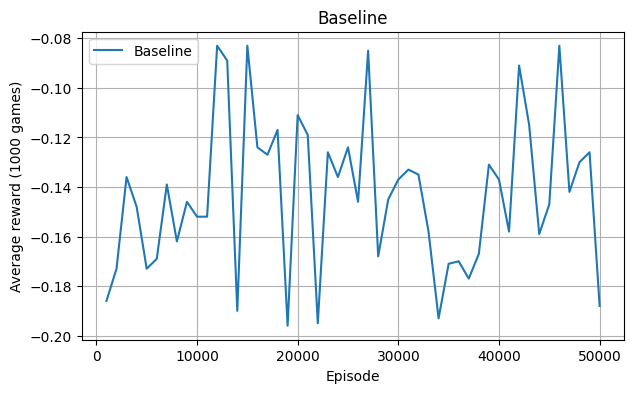

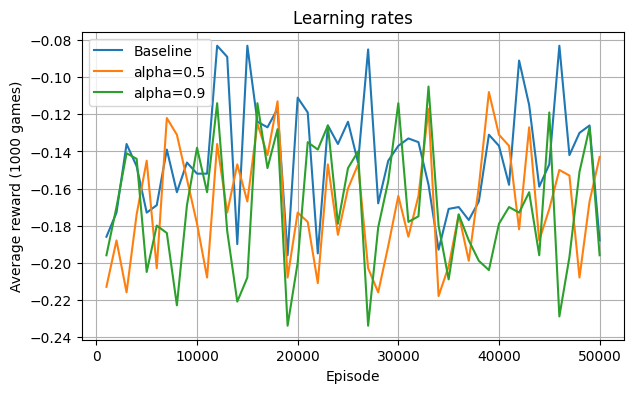

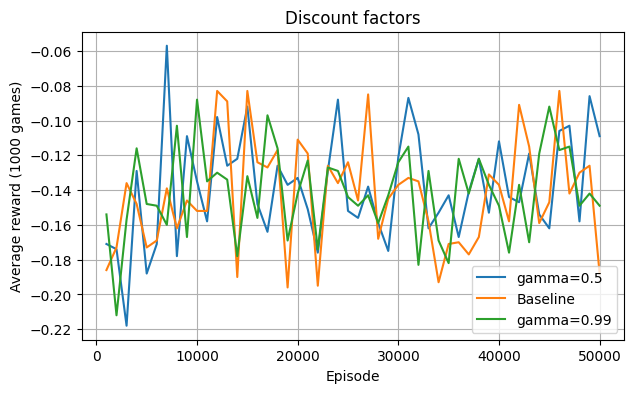

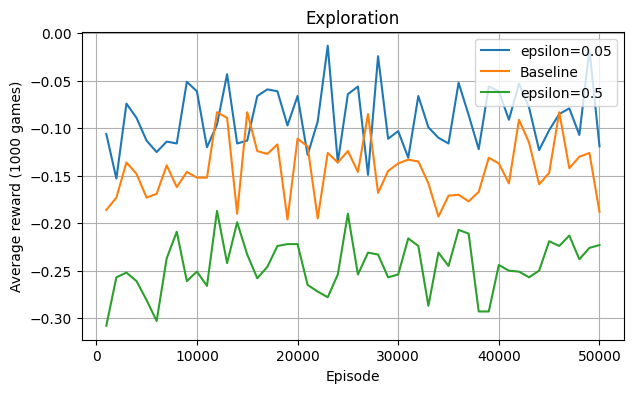

Best setting: gamma=0.99
Baseline: mean=-0.042, wins=44.0%
Best: mean=-0.036, wins=43.4%



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
import gymnasium as gym
import random
import matplotlib.pyplot as plt
import imageio.v2 as imageio
import os
import shutil
from google.colab import files
from IPython.display import Video, display

os.makedirs("results", exist_ok=True)
env = gym.make("Blackjack-v1")
EPISODES = 50000

# Q learning training

def train(alpha, gamma, epsilon):
    random.seed(42)
    env.reset(seed=42)
    q = {}
    rewards = []

    for i in range(EPISODES):
        state, _ = env.reset()
        done = False

        while not done:
            if state not in q:
                q[state] = [0.0, 0.0]

            if random.random() < epsilon:
                action = random.randint(0, 1)
            else:
                action = q[state].index(max(q[state]))

            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated

            if next_state not in q:
                q[next_state] = [0.0, 0.0]

            if done:
                future = 0
            else:
                future = max(q[next_state])

            q[state][action] += alpha * (reward + gamma * future - q[state][action])
            state = next_state

        rewards.append(reward)

    return q, rewards


# C-F
tests = [
    ("Baseline", 0.1, 0.9, 0.2),
    ("alpha=0.5", 0.5, 0.9, 0.2),
    ("alpha=0.9", 0.9, 0.9, 0.2),
    ("gamma=0.5", 0.1, 0.5, 0.2),
    ("gamma=0.99", 0.1, 0.99, 0.2),
    ("epsilon=0.05", 0.1, 0.9, 0.05),
    ("epsilon=0.5", 0.1, 0.9, 0.5)
]

q_tables = {}
rewards = {}
for name, alpha, gamma, epsilon in tests:
    print("Training", name)
    q_tables[name], rewards[name] = train(alpha, gamma, epsilon)

# 4 graphs, 1k episodes
plots = [
    (["Baseline"], "Baseline", "baseline.png"),
    (["Baseline", "alpha=0.5", "alpha=0.9"], "Learning rates", "alpha.png"),
    (["gamma=0.5", "Baseline", "gamma=0.99"], "Discount factors", "gamma.png"),
    (["epsilon=0.05", "Baseline", "epsilon=0.5"], "Exploration", "epsilon.png")
]

for names, title, filename in plots:
    plt.figure(figsize=(7, 4))
    for name in names:
        averages = []
        for i in range(0, EPISODES, 1000):
            averages.append(sum(rewards[name][i:i+1000]) / 1000)
        plt.plot(range(1000, EPISODES+1, 1000), averages, label=name)
    plt.title(title)
    plt.xlabel("Episode")
    plt.ylabel("Average reward (1000 games)")
    plt.legend()
    plt.grid()
    plt.savefig("results/" + filename)
    plt.show()


# G
def evaluate(q, games, seed):
    env.reset(seed=seed)
    scores = []
    for i in range(games):
        state, _ = env.reset()
        done = False
        while not done:
            values = q.get(state, [0.0, 0.0])
            action = values.index(max(values))
            state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
        scores.append(reward)
    return sum(scores) / games, 100 * scores.count(1.0) / games

best = "Baseline"
best_score = -10
for name in q_tables:
    score, win_rate = evaluate(q_tables[name], 500, 123)
    if score > best_score:
        best = name
        best_score = score

baseline_mean, baseline_wins = evaluate(q_tables["Baseline"], 2000, 2026)
best_mean, best_wins = evaluate(q_tables[best], 2000, 2026)

result = (f"Best setting: {best}\n"
          f"Baseline: mean={baseline_mean:.3f}, wins={baseline_wins:.1f}%\n"
          f"Best: mean={best_mean:.3f}, wins={best_wins:.1f}%\n")
print(result)
with open("results/evaluation.txt", "w") as f:
    f.write(result)

# MP4
os.environ["SDL_VIDEODRIVER"] = "dummy"
video_env = gym.make("Blackjack-v1", render_mode="rgb_array")
frames = []
for game in range(5):
    state, _ = video_env.reset(seed=500+game)
    frames.append(video_env.render())
    done = False
    while not done:
        values = q_tables[best].get(state, [0.0, 0.0])
        action = values.index(max(values))
        state, reward, terminated, truncated, _ = video_env.step(action)
        done = terminated or truncated
        frames.append(video_env.render())
video_env.close()

imageio.mimsave("results/blackjack_demo.mp4", frames, fps=2)
display(Video("results/blackjack_demo.mp4", embed=True))

# download the picutres
shutil.make_archive("blackjack_results", "zip", "results")
files.download("blackjack_results.zip")
env.close()